## Домашнее задание 1

### Обучаем LightFM бейзлайн

In [100]:
import pandas as pd
import numpy as np
import scipy.stats as ss
import scipy.special as sp

import lightfm
import lightfm.data as ld
import lightfm.evaluation as lv

import tqdm
import json
import optuna

import tensorboardX as tb
import matplotlib.pyplot as plt

import matplotlib.pyplot as pl
import seaborn as sns

np.random.seed(31337)

In [101]:
data = pd.read_csv("data/contest_1/raw_data/train.csv")
#здесь относительный путь

#data = data[data["time"] > 0.75].copy().reset_index()

#data["test"] = np.random.random(len(data)) > 0.8
print(type(data))
print(len(data))
data.head(10)

<class 'pandas.DataFrame'>
2631427


,user,track,time
0,0dffdaaffb460ead08234a09f625d3e8,4252,0.26
1,a5a049b5d915c48ee66fcf482818b30b,326,1.00
2,803deb36c0f2dae7306bec7ce5a0a2a0,9959,0.05
3,c7510a5422f0f55f02be7981b1158f27,4042,0.26
4,0181ae3f7155d55fa176840320e0c566,11371,0.04
5,5eef0fa3293c362958bf97fc33966790,1318,0.43
6,3c3fabe86db51d24fdbff97d6ecb3738,4400,0.44
7,a5a049b5d915c48ee66fcf482818b30b,1014,0.04
8,e4c84490860dbb93b1cc06b5b22e2633,5609,1.00
9,bb83d65e329e335f7b14270c6ef299da,385,1.00


группируем пользователей и треки по числу прослушанных песен и суммарному времени прослушивания.

In [102]:
grouped_data = data.groupby(['user', 'track']).agg(
    total_time =('time','sum'),
    count = ('user','size')
    ).reset_index()
#data = data.groupby(['user', 'track']).size().reset_index(name="count")
grouped_data = grouped_data[grouped_data["total_time"] > 0.75].copy().reset_index()
print(len(data))
print(len(grouped_data))

grouped_data.head(10)

2631427
462465


,index,user,track,total_time,count
0,0,00031e5a08989865ae15e4afcd69af5f,3,0.81,1
1,1,00031e5a08989865ae15e4afcd69af5f,12,1.00,1
2,2,00031e5a08989865ae15e4afcd69af5f,14,1.00,1
3,3,00031e5a08989865ae15e4afcd69af5f,18,2.00,2
4,4,00031e5a08989865ae15e4afcd69af5f,19,2.00,2
5,5,00031e5a08989865ae15e4afcd69af5f,54,0.98,1
6,7,00031e5a08989865ae15e4afcd69af5f,80,0.98,1
7,8,00031e5a08989865ae15e4afcd69af5f,82,1.00,1
8,9,00031e5a08989865ae15e4afcd69af5f,84,3.00,3
9,10,00031e5a08989865ae15e4afcd69af5f,85,2.00,2


In [103]:
grouped_data["if_test"] = np.random.random(len(grouped_data)) > 0.8
print(grouped_data)

          index                              user  track  total_time  count  \
0             0  00031e5a08989865ae15e4afcd69af5f      3        0.81      1   
1             1  00031e5a08989865ae15e4afcd69af5f     12        1.00      1   
2             2  00031e5a08989865ae15e4afcd69af5f     14        1.00      1   
3             3  00031e5a08989865ae15e4afcd69af5f     18        2.00      2   
4             4  00031e5a08989865ae15e4afcd69af5f     19        2.00      2   
...         ...                               ...    ...         ...    ...   
462460  2500118  fffd7073bd235ca06f14f966e8fe0f04  15487        1.00      1   
462461  2500123  fffd7073bd235ca06f14f966e8fe0f04  15761        0.89      1   
462462  2500124  fffd7073bd235ca06f14f966e8fe0f04  16013        0.91      1   
462463  2500126  fffd7073bd235ca06f14f966e8fe0f04  16104        1.00      1   
462464  2500129  fffd7073bd235ca06f14f966e8fe0f04  16164        0.86      1   

        if_test  
0         False  
1          True

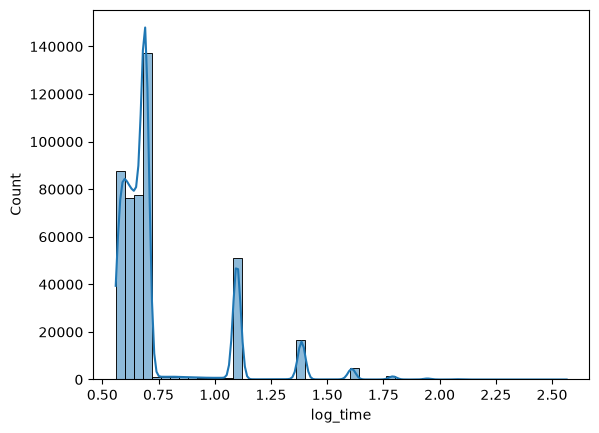

In [104]:
grouped_data["log_time"] = np.log1p(grouped_data["total_time"])
sns.histplot(grouped_data["log_time"], bins = 50, kde = True)
plt.show()

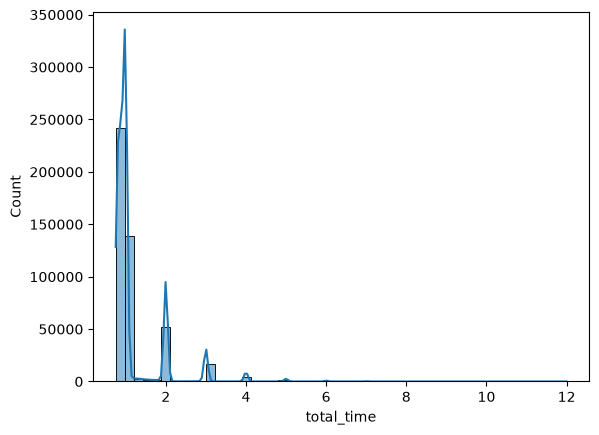

In [105]:
sns.histplot(grouped_data["total_time"], bins = 50, kde = True)
plt.show()

In [106]:
print(grouped_data["total_time"].quantile([0.1, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99]))

0.10    0.79
0.25    0.85
0.50    0.96
0.75    1.00
0.90    2.00
0.95    3.00
0.99    4.00
Name: total_time, dtype: float64


In [107]:
print(grouped_data["total_time"].describe())

count    462465.000000
mean          1.168605
std           0.654107
min           0.750000
25%           0.850000
50%           0.960000
75%           1.000000
max          12.000000
Name: total_time, dtype: float64


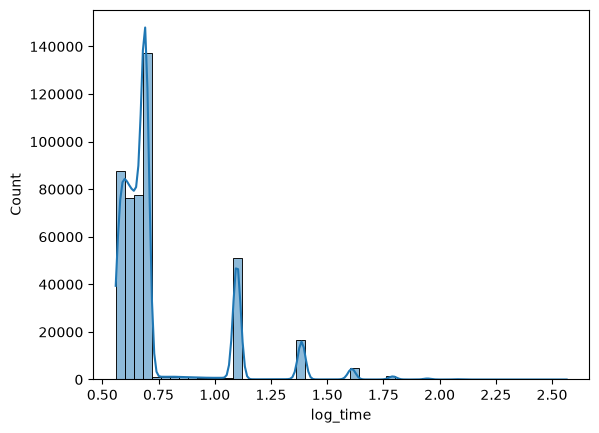

In [108]:
sns.histplot(grouped_data["log_time"], bins = 50, kde = True)
plt.show()

In [109]:
user_counts = grouped_data.loc[~grouped_data["if_test"], "user"].value_counts()
users = set(user_counts[user_counts >= 5].index.values)

len(users)

9996

In [110]:
track_counts = grouped_data.loc[~grouped_data["if_test"], "track"].value_counts()
tracks = set(track_counts[track_counts >= 3].index.values)

len(tracks)

16100

In [111]:
train_data = grouped_data[~grouped_data["if_test"] & grouped_data["user"].isin(users) & grouped_data["track"].isin(tracks)]
test_data = grouped_data[grouped_data["if_test"] & grouped_data["user"].isin(users) & grouped_data["track"].isin(tracks)]

len(train_data), len(test_data)

(370276, 91859)

мапинг для lightfm

In [113]:
dataset = ld.Dataset()
dataset.fit(users, tracks)

In [ ]:
создание матрицы взаимодействий

In [114]:
train_interactions, train_weights = dataset.build_interactions(train_data[["user", "track","log_time"]].itertuples(index=False, name=None))
test_interactions, _ = dataset.build_interactions(test_data[["user", "track","log_time"]].itertuples(index=False, name=None))

In [ ]:
используем optuna для подбора гиперпараметров

In [122]:

def ndcg_at_k(model, test_interactions, train_interactions=None, k=10, num_threads=4):
    # predict_rank возвращает разреженную матрицу, где для каждого пользователя 
    # лежат ранги только тех треков, которые есть у него в тесте.
    ranks = model.predict_rank(
        test_interactions,
        train_interactions=train_interactions,
        num_threads=num_threads
    )
    ranks_csr = ranks.tocsr()
    
    ndcg_scores = []
    for user_idx in range(ranks_csr.shape[0]):
        start = ranks_csr.indptr[user_idx]
        end = ranks_csr.indptr[user_idx + 1]
        
        # Если у пользователя нет тестовых взаимодействий — пропускаем
        if start == end:
            continue
            
        # Достаём ранги (0 - лучший, 1 - второй и т.д.) и сортируем
        user_ranks = ranks_csr.data[start:end]
        user_ranks.sort()
        user_ranks = user_ranks[:k]  # берём только топ-k
        
        # Считаем DCG (чем меньше ранг, тем выше вклад)
        dcg = np.sum(1.0 / np.log2(user_ranks + 2))
        
        # Считаем идеальный IDCG (если бы все треки шли по порядку 0,1,2...)
        ideal_ranks = np.arange(len(user_ranks))
        idcg = np.sum(1.0 / np.log2(ideal_ranks + 2))
        
        if idcg > 0:
            ndcg_scores.append(dcg / idcg)
        else:
            ndcg_scores.append(0.0)
            
    return np.array(ndcg_scores)

In [127]:
from lightfm import LightFM
#optuna запускает эту функцию, чтобы перебирать параметры
def objective(trial):

    #параметры перебора
    loss = trial.suggest_categorical('loss',['warp','bpr'])
    #размер латентных векторов
    no_components = trial.suggest_int('no_components', 10, 50)
    learning_rate = trial.suggest_float('learning_rate',0.01, 0.1, log=True)
    epochs = trial.suggest_int('epochs', 10, 30)
      # Регуляризация (от 10^-6 до 10^-1)
    user_alpha = trial.suggest_float('user_alpha', 1e-6, 1e-1, log=True)
    item_alpha = trial.suggest_float('item_alpha', 1e-6, 1e-1, log=True)
    max_sampled = trial.suggest_int('max_sampled', 10, 100)

    #создаем и обучаем модель
    model = LightFM(
        loss=loss,
        no_components=no_components,
        learning_rate=learning_rate,
        user_alpha=user_alpha,
        item_alpha=item_alpha,
        max_sampled=max_sampled,
        random_state=42
    )
    
    model.fit(
        train_interactions,
        sample_weight=train_weights,
        epochs=epochs,
        num_threads=4
    )

    #считаем метрику
   #нужно среднее значение NDCG по всем пользователям
    ndcg_scores = ndcg_at_k(
        model = model, 
        test_interactions=test_interactions, 
        train_interactions=train_interactions, # Важно: чтобы не рекомендовать то, что уже в трейне
        k=10, # Оцениваем топ-10 рекомендаций
        num_threads=4
    )
    mean_ndcg = ndcg_scores.mean()

    return mean_ndcg

In [128]:
#создаем исследование через оптуну
study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=30)
best_params = study.best_params

best_params

[I 2026-10-21 17:09:07,721] A new study created in memory with name: no-name-dc997f1c-abc4-4ed5-ada9-7cfab69707c5
[I 2026-10-21 17:09:11,831] Trial 0 finished with value: 0.15107260146231286 and parameters: {'loss': 'bpr', 'no_components': 47, 'learning_rate': 0.05214291134302019, 'epochs': 21, 'user_alpha': 0.003801477481846328, 'item_alpha': 0.0019458660189200674, 'max_sampled': 97}. Best is trial 0 with value: 0.15107260146231286.
[I 2026-10-21 17:09:14,379] Trial 1 finished with value: 0.1680399661933498 and parameters: {'loss': 'bpr', 'no_components': 15, 'learning_rate': 0.02472153474516153, 'epochs': 13, 'user_alpha': 0.0007597473030146263, 'item_alpha': 0.00035841667472756816, 'max_sampled': 34}. Best is trial 1 with value: 0.1680399661933498.
[I 2026-10-21 17:09:18,383] Trial 2 finished with value: 0.14601458249956834 and parameters: {'loss': 'warp', 'no_components': 19, 'learning_rate': 0.010126636978802919, 'epochs': 23, 'user_alpha': 1.0257960627334586e-06, 'item_alpha': 0.

{'loss': 'bpr',
 'no_components': 37,
 'learning_rate': 0.0641833944169777,
 'epochs': 29,
 'user_alpha': 4.089657490196628e-06,
 'item_alpha': 2.339411049140999e-06,
 'max_sampled': 30}

In [138]:
print(best_params["loss"])

bpr


In [155]:

model, precisions_at = fit_model(
    epochs=100,
    at=10,
    loss='warp',
    no_components=50, 
    learning_rate=0.01, 
    max_sampled=100,
    user_alpha=0.0,
    item_alpha=0.01,
    verbose=True,
)

0:	0.004944999702274799 +/- 0.0004466168174985796
1:	0.006055101286619902 +/- 0.0005065130535513163
2:	0.009123019874095917 +/- 0.0006547264056280255
3:	0.011353314854204655 +/- 0.0007494035526178777
4:	0.01290745846927166 +/- 0.0008039736421778798
5:	0.014764354564249516 +/- 0.0008588227792643011
6:	0.01662125438451767 +/- 0.0009101941832341254
7:	0.0186295285820961 +/- 0.0009715065243653953
8:	0.020446060225367546 +/- 0.0010228444589301944
9:	0.022212130948901176 +/- 0.0010630534961819649
10:	0.024180039763450623 +/- 0.0011124321026727557
11:	0.026036936789751053 +/- 0.0011524440487846732
12:	0.028025029227137566 +/- 0.001192573457956314
13:	0.029659908264875412 +/- 0.0012224745005369186
14:	0.03123423084616661 +/- 0.0012492290697991848
15:	0.032626908272504807 +/- 0.0012746350839734077
16:	0.03382783383131027 +/- 0.0012986477231606841
17:	0.03479665145277977 +/- 0.0013163227122277021
18:	0.03597739338874817 +/- 0.001346620381809771
19:	0.03726914897561073 +/- 0.0013619688106700778
2

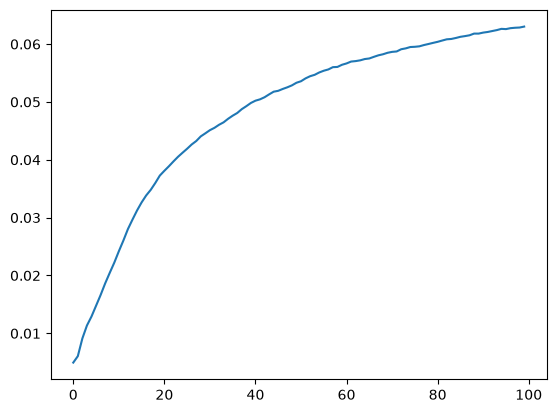

In [156]:
figure, ax = pl.subplots()

ax.plot(np.arange(len(precisions_at)), precisions_at)

pass

### Готовим данные для сабмита

In [157]:
submit_data = pd.read_csv("data/contest_1/raw_data/test.csv")
submit_data.head()

,user,track
0,abb1b98c5cbcff30d8ca270ca437ddb8,10901
1,bae0a9b4027abefe8f55351183f19604,7685
2,e981fcd33e48ea5de3e7e2f784a47566,9346
3,41806b51385ff04e6edcd28096724778,490
4,84d430b459ad7fbfe20a8b3902848a82,1027


In [158]:
filtered_submit_data = submit_data[submit_data["user"].isin(users) & submit_data["track"].isin(tracks)].drop_duplicates().copy()

In [159]:
filtered_submit_data["score"] = model.predict(
    filtered_submit_data["user"].map(dataset.mapping()[0]).values,
    filtered_submit_data["track"].map(dataset.mapping()[2]).values,
)

<Axes: xlabel='score', ylabel='Count'>

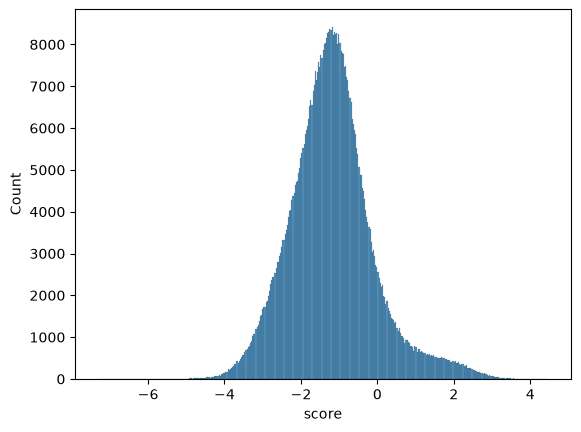

In [160]:
sns.histplot(filtered_submit_data["score"])

In [161]:
scored_submit_data = pd.merge(
    submit_data,
    filtered_submit_data,
    left_on=["user", "track"],
    right_on=["user", "track"],
    how="left"
)

# Fill missing scores with small random numbers
scored_submit_data["score"] = scored_submit_data["score"].map(lambda s : np.random.random() * 0.01 if pd.isna(s) else np.exp(s))
# scored_submit_data["score"] = scored_submit_data["score"].map(lambda s : np.random.random())
# scored_submit_data["score"] = scored_submit_data["score"].map(lambda s : 0.0)

scored_submit_data.head()

,user,track,score
0,abb1b98c5cbcff30d8ca270ca437ddb8,10901,0.512966
1,bae0a9b4027abefe8f55351183f19604,7685,0.739949
2,e981fcd33e48ea5de3e7e2f784a47566,9346,0.071463
3,41806b51385ff04e6edcd28096724778,490,0.699369
4,84d430b459ad7fbfe20a8b3902848a82,1027,0.066487


In [162]:
version = 3
file_path = f"data/contest_1/processed/submit_v{version}.csv"
scored_submit_data.to_csv(file_path, index=False)